In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

Mounted at /content/gdrive


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tabulate import tabulate
import requests
import json
import itertools
%matplotlib inline

In [ ]:
import sklearn.metrics as metrics
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer

In [ ]:
path1 = '/content/gdrive/MyDrive/GAIAData/80-20/TmaxData_2010_2014.xlsx'
train_data = pd.read_excel(path1)
train_data

# path2 = '/content/gdrive/MyDrive/GAIAData/80-20/TmaxData_2010_2014.xlsx'
# train_data_tmax = pd.read_excel(path2)
# train_data_tmax

path3 = '/content/gdrive/MyDrive/GAIAData/80-20/TMAX_Test_2010_2014.xlsx'
test_data = pd.read_excel(path3)
test_data

,Date,Latitude,Longitude,IMD,NASA
0,2012-11-06,11.5,79.5,32.889999,30.43
1,2011-02-05,10.5,78.5,32.209999,30.12
2,2011-03-09,8.5,78.5,34.689999,28.54
3,2010-10-05,8.5,78.5,31.340000,28.48
4,2013-10-10,11.5,78.5,33.720001,29.49
5,2012-07-06,11.5,79.5,38.549999,37.19
6,2013-07-12,10.5,79.5,34.889999,36.18
7,2011-08-27,10.5,78.5,34.439999,35.38
8,2010-11-07,11.5,78.5,25.030001,25.80
9,2013-03-15,10.5,77.5,32.790001,35.80


In [ ]:
train_data['Month'] = pd.to_datetime(train_data['Date']).dt.month #Extracting the months from the date column to determine its season (TRAIN)
train_data

test_data['Month'] = pd.to_datetime(test_data['Date']).dt.month #Extracting the months from the date column to determine its season (TRAIN)
test_data

,Date,Latitude,Longitude,IMD,NASA,Month
0,2012-11-06,11.5,79.5,32.889999,30.43,11
1,2011-02-05,10.5,78.5,32.209999,30.12,2
2,2011-03-09,8.5,78.5,34.689999,28.54,3
3,2010-10-05,8.5,78.5,31.340000,28.48,10
4,2013-10-10,11.5,78.5,33.720001,29.49,10
5,2012-07-06,11.5,79.5,38.549999,37.19,7
6,2013-07-12,10.5,79.5,34.889999,36.18,7
7,2011-08-27,10.5,78.5,34.439999,35.38,8
8,2010-11-07,11.5,78.5,25.030001,25.80,11
9,2013-03-15,10.5,77.5,32.790001,35.80,3


In [ ]:
season_mapping = {
    12: 'Winter',
    1: 'Winter',
    2: 'Winter',
    3: 'Pre-Summer',
    4: 'Pre-Summer',
    5: 'Summer',
    6: 'Summer',
    7: 'Southwest Monsoon',
    8: 'Southwest Monsoon',
    9: 'Autumn',
    10: 'Autumn',
    11: 'Northeast Monsoon'
}

train_data['season'] = train_data['Month'].map(season_mapping)
train_data

test_data['season'] = test_data['Month'].map(season_mapping)
test_data

,Date,Latitude,Longitude,IMD,NASA,Month,season
0,2012-11-06,11.5,79.5,32.889999,30.43,11,Northeast Monsoon
1,2011-02-05,10.5,78.5,32.209999,30.12,2,Winter
2,2011-03-09,8.5,78.5,34.689999,28.54,3,Pre-Summer
3,2010-10-05,8.5,78.5,31.340000,28.48,10,Autumn
4,2013-10-10,11.5,78.5,33.720001,29.49,10,Autumn
5,2012-07-06,11.5,79.5,38.549999,37.19,7,Southwest Monsoon
6,2013-07-12,10.5,79.5,34.889999,36.18,7,Southwest Monsoon
7,2011-08-27,10.5,78.5,34.439999,35.38,8,Southwest Monsoon
8,2010-11-07,11.5,78.5,25.030001,25.80,11,Northeast Monsoon
9,2013-03-15,10.5,77.5,32.790001,35.80,3,Pre-Summer


In [ ]:
one_hot_encoded = pd.get_dummies(train_data['season'])
train_encoded = pd.concat([train_data, one_hot_encoded], axis=1) # Concatenates the original dataframe with the encoded season columns (TRAIN)
train_encoded #Data after encoding (TRAIN)

one_hot_encoded = pd.get_dummies(test_data['season'])
test_encoded = pd.concat([test_data, one_hot_encoded], axis=1) # Concatenates the original dataframe with the encoded season columns (TRAIN)
test_encoded #Data after encoding (TRAIN)

,Date,Latitude,Longitude,IMD,NASA,Month,season,Autumn,Northeast Monsoon,Pre-Summer,Southwest Monsoon,Summer,Winter
0,2012-11-06,11.5,79.5,32.889999,30.43,11,Northeast Monsoon,False,True,False,False,False,False
1,2011-02-05,10.5,78.5,32.209999,30.12,2,Winter,False,False,False,False,False,True
2,2011-03-09,8.5,78.5,34.689999,28.54,3,Pre-Summer,False,False,True,False,False,False
3,2010-10-05,8.5,78.5,31.340000,28.48,10,Autumn,True,False,False,False,False,False
4,2013-10-10,11.5,78.5,33.720001,29.49,10,Autumn,True,False,False,False,False,False
5,2012-07-06,11.5,79.5,38.549999,37.19,7,Southwest Monsoon,False,False,False,True,False,False
6,2013-07-12,10.5,79.5,34.889999,36.18,7,Southwest Monsoon,False,False,False,True,False,False
7,2011-08-27,10.5,78.5,34.439999,35.38,8,Southwest Monsoon,False,False,False,True,False,False
8,2010-11-07,11.5,78.5,25.030001,25.80,11,Northeast Monsoon,False,True,False,False,False,False
9,2013-03-15,10.5,77.5,32.790001,35.80,3,Pre-Summer,False,False,True,False,False,False


In [ ]:
train_encoded = train_encoded.drop(['Month', 'season','Autumn', 'Date', 'Latitude', 'Longitude'], axis = 1)
train_encoded

test_encoded = test_encoded.drop(['Month', 'season','Autumn', 'Date', 'Latitude', 'Longitude'], axis = 1)
test_encoded

,IMD,NASA,Northeast Monsoon,Pre-Summer,Southwest Monsoon,Summer,Winter
0,32.889999,30.43,True,False,False,False,False
1,32.209999,30.12,False,False,False,False,True
2,34.689999,28.54,False,True,False,False,False
3,31.340000,28.48,False,False,False,False,False
4,33.720001,29.49,False,False,False,False,False
5,38.549999,37.19,False,False,True,False,False
6,34.889999,36.18,False,False,True,False,False
7,34.439999,35.38,False,False,True,False,False
8,25.030001,25.80,True,False,False,False,False
9,32.790001,35.80,False,True,False,False,False


In [ ]:
# Defining the dependent/target and independent variables
y_train = train_encoded['IMD'] #Target variable for TRAINING SET
X_train = train_encoded.drop(['IMD'], axis = 1) #Independent variable for TRAINING SET
Y_test = test_encoded['IMD']
X_test = test_encoded.drop(['IMD'], axis = 1)

In [ ]:
imputer = SimpleImputer(strategy="mean")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
# prompt: print a dataframe showing the predicted value and the y_test vlaue in subsequent columns and a third column with the diference between them

df = pd.DataFrame({'Predicted Value': y_pred, 'Y_test': Y_test})
df['Difference'] = df['Predicted Value'] - df['Y_test']
print(df.to_string())


    Predicted Value     Y_test  Difference
0         30.664484  32.889999   -2.225516
1         30.640668  32.209999   -1.569331
2         32.862606  34.689999   -1.827392
3         31.822818  31.340000    0.482818
4         32.158639  33.720001   -1.561362
5         35.169098  38.549999   -3.380901
6         34.833277  34.889999   -0.056722
7         34.567280  34.439999    0.127281
8         29.125025  25.030001    4.095024
9         35.276531  32.790001    2.486530
10        32.233154  35.410000   -3.176846
11        35.048935  38.990002   -3.941066
12        34.177794  35.810688   -1.632894
13        30.414571  28.342922    2.071649
14        35.318258  36.889999   -1.571742
15        34.219192  34.560001   -0.340809
16        33.580799  36.860001   -3.279202
17        36.373770  34.660000    1.713770
18        30.891828  28.889999    2.001828
19        35.148684  32.720001    2.428683


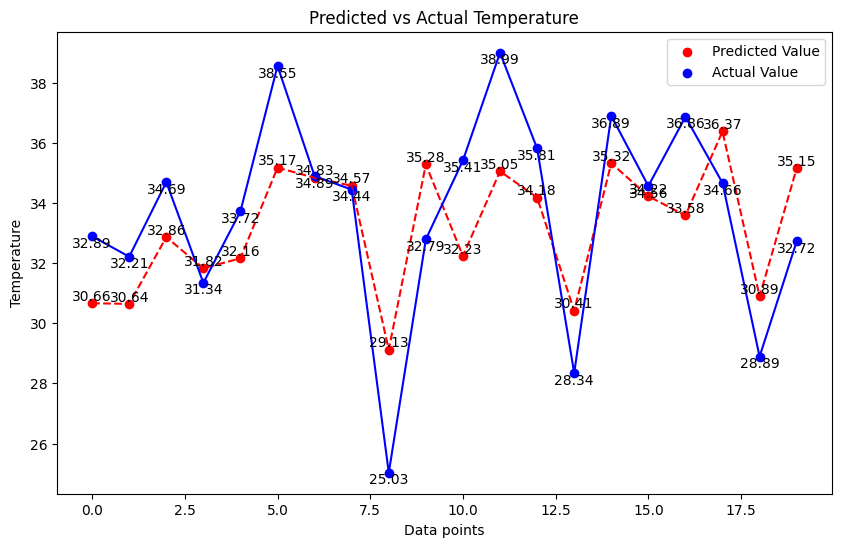

In [ ]:
# prompt: plot a graph showing y_pred in one colour with the points labeled on the graph and Y_test line in another colur with points on the graph. Can you show the value of the dots on the graph itself

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot the predicted values
plt.scatter(range(len(y_pred)), y_pred, color='red', label='Predicted Value')
plt.plot(range(len(y_pred)), y_pred, color='red', linestyle='--')

# Plot the actual values
plt.scatter(range(len(Y_test)), Y_test, color='blue', label='Actual Value')
plt.plot(range(len(Y_test)), Y_test, color='blue')

# Add labels and title
plt.xlabel('Data points')
plt.ylabel('Temperature')
plt.title('Predicted vs Actual Temperature')

# Add values to the data points
for i, val in enumerate(y_pred):
    plt.text(i, val, str(round(val, 2)), ha='center', va='bottom')

for i, val in enumerate(Y_test):
    plt.text(i, val, str(round(val, 2)), ha='center', va='top')

# Add legend and show plot
plt.legend()
plt.show()


In [ ]:
# prompt: print the error metrics for the model - mae, mse, r2

print("Mean Absolute Error (MAE):", metrics.mean_absolute_error(y_pred, Y_test))
print("Mean Squared Error (MSE):", metrics.mean_squared_error(y_pred, Y_test))
print("R-squared:", metrics.r2_score(y_pred, Y_test))


Mean Absolute Error (MAE): 1.998568258905347
Mean Squared Error (MSE): 5.32964716430263
R-squared: -0.2791897856891641


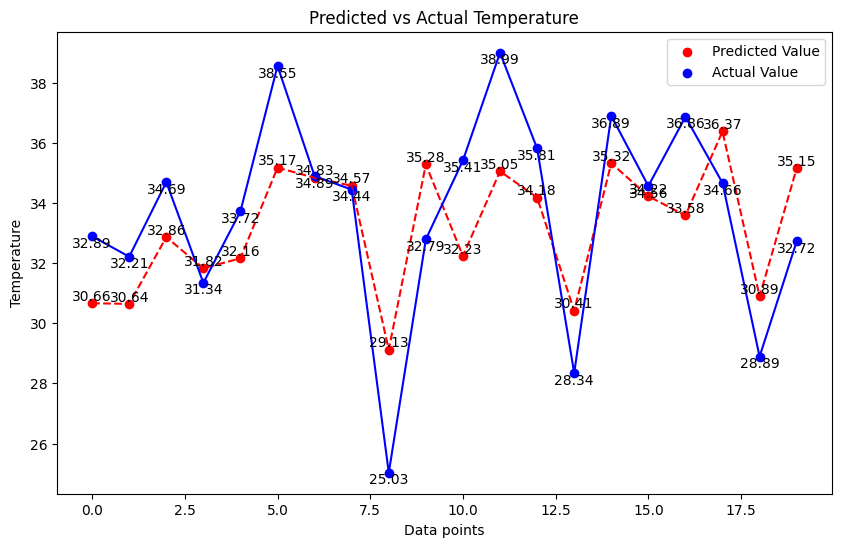

In [ ]:
# prompt: y_actual vs y_pred

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot the predicted values
plt.scatter(range(len(y_pred)), y_pred, color='red', label='Predicted Value')
plt.plot(range(len(y_pred)), y_pred, color='red', linestyle='--')

# Plot the actual values
plt.scatter(range(len(Y_test)), Y_test, color='blue', label='Actual Value')
plt.plot(range(len(Y_test)), Y_test, color='blue')

# Add labels and title
plt.xlabel('Data points')
plt.ylabel('Temperature')
plt.title('Predicted vs Actual Temperature')

# Add values to the data points
for i, val in enumerate(y_pred):
    plt.text(i, val, str(round(val, 2)), ha='center', va='bottom')

for i, val in enumerate(Y_test):
    plt.text(i, val, str(round(val, 2)), ha='center', va='top')

# Add legend and show plot
plt.legend()
plt.show()
